In [3]:
import os
import sys
import json
import math
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import torch

# Configure visualization styling for publication-grade figures
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"

# =====================================================================
# 1. DYNAMIC PATH AUTO-DETECTION & MASTER METADATA INGESTION
# =====================================================================
CURRENT_DIR = Path.cwd().resolve()

if (CURRENT_DIR / "metadata").exists():
    BTECH_ROOT = CURRENT_DIR
elif (CURRENT_DIR / "BTech_Project" / "metadata").exists():
    BTECH_ROOT = CURRENT_DIR / "BTech_Project"
elif (CURRENT_DIR.parent / "metadata").exists():
    BTECH_ROOT = CURRENT_DIR.parent
elif (CURRENT_DIR.parent.parent / "metadata").exists():
    BTECH_ROOT = CURRENT_DIR.parent.parent
else:
    raise FileNotFoundError("Could not auto-locate 'BTech_Project/metadata' directory.")

METADATA_DIR = BTECH_ROOT / "metadata"
PLOTS_DIR = BTECH_ROOT / "results" / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

manifest_file = METADATA_DIR / "unified_master_manifest.csv"
label_map_file = METADATA_DIR / "unified_label_map.json"
summary_file = METADATA_DIR / "class_distribution_summary.csv"

assert manifest_file.exists(), f"Missing master manifest: {manifest_file}. Please run notebook 01 first."
assert label_map_file.exists(), f"Missing label map: {label_map_file}."

df_master = pd.read_csv(manifest_file)
with open(label_map_file, "r", encoding="utf-8") as f:
    LABEL_TO_ID = json.load(f)
ID_TO_LABEL = {v: k for k, v in LABEL_TO_ID.items()}

# =====================================================================
# 2. HARDWARE & ENVIRONMENT AUDIT
# =====================================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 75)
print("  PHASE 2: EXPLORATORY DATA ANALYSIS & CLINICAL QUALITY CONTROL")
print("=" * 75)
print(f"\u2713 Project Root         : {BTECH_ROOT}")
print(f"\u2713 Master Manifest File : {manifest_file} (Samples: {len(df_master):,})")
print(f"\u2713 Label Mapping File   : {label_map_file} (Classes: {len(LABEL_TO_ID)})")
print(f"\u2713 Figures Target Dir   : {PLOTS_DIR}")
print("-" * 75)
print(f"\u2713 Compute Device       : {DEVICE}")
if DEVICE.type == "cuda":
    print(f"\u2713 GPU Accelerator      : {torch.cuda.get_device_name(0)}")
    print(f"\u2713 GPU VRAM Available   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print("=" * 75)
print(f"Master dataset successfully loaded ({len(df_master):,} records across {len(LABEL_TO_ID)} classes). Ready for EDA.")


  PHASE 2: EXPLORATORY DATA ANALYSIS & CLINICAL QUALITY CONTROL
✓ Project Root         : C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project
✓ Master Manifest File : C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\metadata\unified_master_manifest.csv (Samples: 22,991)
✓ Label Mapping File   : C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\metadata\unified_label_map.json (Classes: 25)
✓ Figures Target Dir   : C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots
---------------------------------------------------------------------------
✓ Compute Device       : cuda
✓ GPU Accelerator      : NVIDIA GeForce RTX 5050 Laptop GPU
✓ GPU VRAM Available   : 8.55 GB
Master dataset successfully loaded (22,991 records across 25 classes). Ready for EDA.


  PROFILING CLINICAL CLASS DISTRIBUTION & IMBALANCE RATIO
✓ Total Unique Clinical Images : 22,991
✓ Tier 1 (Core Focus / NTDs)   : 6,581 (28.6%) across 9 classes
✓ Tier 2 (Routine Primary Care): 16,410 (71.4%) across 16 classes
✓ Majority Class               : Malignant_Melanoma (N = 2,818, 12.26%)
✓ Minority Class               : Kaposi_Sarcoma (N = 43, 0.19%)
✓ Imbalance Ratio (IR)         : 65.53:1


C:\Users\kvcsu_ht23nk8\AppData\Local\Temp\ipykernel_15948\637929118.py:95: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_bar.set_yticklabels(labels, fontsize=10)


✓ Figure successfully saved to: C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\01_class_distribution_and_tiers.png


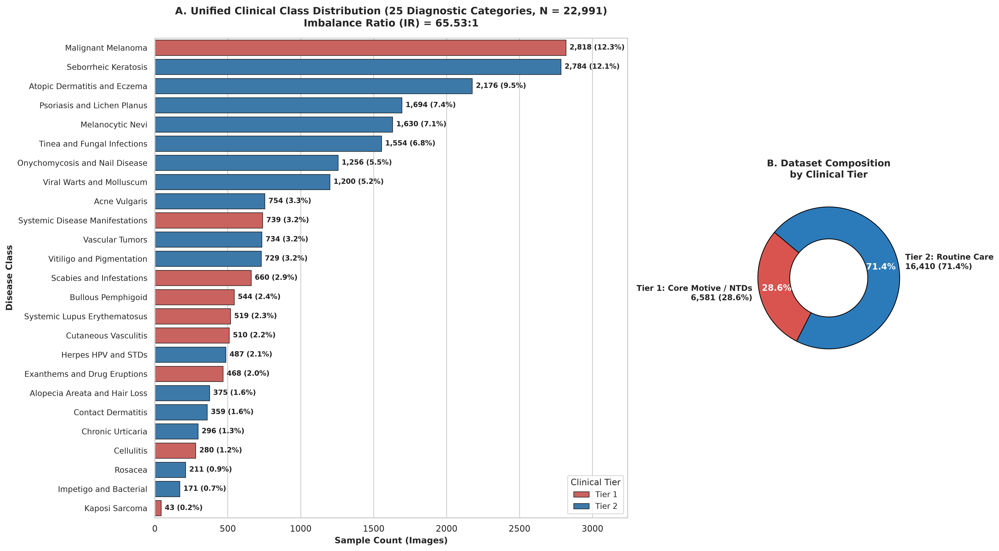

In [4]:
# =====================================================================
# 1. COMPUTE CLASS DISTRIBUTION & IMBALANCE METRICS
# =====================================================================
print("=" * 75)
print("  PROFILING CLINICAL CLASS DISTRIBUTION & IMBALANCE RATIO")
print("=" * 75)

# Aggregate counts per class and clinical tier
class_counts = (
    df_master.groupby(["unified_class", "clinical_tier"])
    .size()
    .reset_index(name="count")
)
class_counts = class_counts.sort_values(by="count", ascending=False).reset_index(drop=True)

total_images = len(df_master)
class_counts["percentage"] = (class_counts["count"] / total_images) * 100
class_counts["cumulative_pct"] = class_counts["percentage"].cumsum()

n_max = class_counts["count"].max()
n_min = class_counts["count"].min()
imbalance_ratio = n_max / n_min

max_class = class_counts.iloc[0]["unified_class"]
min_class = class_counts.iloc[-1]["unified_class"]

tier_counts = df_master["clinical_tier"].value_counts()
tier1_n = tier_counts.get("Tier 1", 0)
tier2_n = tier_counts.get("Tier 2", 0)

print(f"✓ Total Unique Clinical Images : {total_images:,}")
print(f"✓ Tier 1 (Core Focus / NTDs)   : {tier1_n:,} ({tier1_n / total_images * 100:.1f}%) across 9 classes")
print(f"✓ Tier 2 (Routine Primary Care): {tier2_n:,} ({tier2_n / total_images * 100:.1f}%) across 16 classes")
print(f"✓ Majority Class               : {max_class} (N = {n_max:,}, {n_max / total_images * 100:.2f}%)")
print(f"✓ Minority Class               : {min_class} (N = {n_min:,}, {n_min / total_images * 100:.2f}%)")
print(f"✓ Imbalance Ratio (IR)         : {imbalance_ratio:.2f}:1")
print("=" * 75)

# =====================================================================
# 2. GENERATE PUBLICATION-GRADE DUAL-PANEL FIGURE
# =====================================================================
fig, (ax_bar, ax_pie) = plt.subplots(
    nrows=1, 
    ncols=2, 
    figsize=(18, 10), 
    gridspec_kw={"width_ratios": [3.2, 1.2]}
)

# Custom clinical palette
tier_palette = {
    "Tier 1": "#d9534f",  # Alert red/coral for high clinical urgency & NTDs
    "Tier 2": "#2b7bba"   # Clinical blue for routine outpatient dermatology
}

# --- Panel A: Horizontal Bar Chart ---
sns.barplot(
    data=class_counts,
    y="unified_class",
    x="count",
    hue="clinical_tier",
    palette=tier_palette,
    dodge=False,
    ax=ax_bar,
    edgecolor="black",
    linewidth=0.6
)

# Annotate each bar with exact count and percentage
for idx, row in class_counts.iterrows():
    val = row["count"]
    pct = row["percentage"]
    ax_bar.text(
        val + 25, 
        idx, 
        f"{val:,} ({pct:.1f}%)", 
        va="center", 
        fontsize=9, 
        fontweight="bold", 
        color="#222222"
    )

ax_bar.set_title(
    f"A. Unified Clinical Class Distribution (25 Diagnostic Categories, N = {total_images:,})\nImbalance Ratio (IR) = {imbalance_ratio:.2f}:1", 
    fontsize=13, 
    fontweight="bold", 
    pad=15
)
ax_bar.set_xlabel("Sample Count (Images)", fontsize=11, fontweight="bold")
ax_bar.set_ylabel("Disease Class", fontsize=11, fontweight="bold")
ax_bar.set_xlim(0, n_max * 1.15)
ax_bar.legend(title="Clinical Tier", frameon=True, loc="lower right", fontsize=10, title_fontsize=11)

# Format y-axis labels: replace underscores with spaces
labels = [item.get_text().replace("_", " ") for item in ax_bar.get_yticklabels()]
ax_bar.set_yticklabels(labels, fontsize=10)

# --- Panel B: Donut Chart for Clinical Tiers ---
pie_data = [tier1_n, tier2_n]
pie_labels = [
    f"Tier 1: Core Motive / NTDs\n{tier1_n:,} ({tier1_n/total_images*100:.1f}%)", 
    f"Tier 2: Routine Care\n{tier2_n:,} ({tier2_n/total_images*100:.1f}%)"
]
pie_colors = [tier_palette["Tier 1"], tier_palette["Tier 2"]]

wedges, texts, autotexts = ax_pie.pie(
    pie_data,
    labels=pie_labels,
    colors=pie_colors,
    autopct="%1.1f%%",
    pctdistance=0.75,
    startangle=140,
    wedgeprops=dict(width=0.45, edgecolor="black", linewidth=1.0)
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight("bold")
    at.set_color("white")
for t in texts:
    t.set_fontsize(10)
    t.set_fontweight("bold")

ax_pie.set_title("B. Dataset Composition\nby Clinical Tier", fontsize=12, fontweight="bold", pad=15)

plt.tight_layout()

# =====================================================================
# 3. SAVE AND DISPLAY
# =====================================================================
plot_path = PLOTS_DIR / "01_class_distribution_and_tiers.png"
plt.savefig(plot_path, bbox_inches="tight", dpi=300)
print(f"✓ Figure successfully saved to: {plot_path}")
plt.show()

  PROFILING RESOLUTION, ASPECT RATIOS & COLOR MODES (22,991 IMAGES)


Scanning Image Headers: 100%|██████████| 22991/22991 [00:00<00:00, 76788.39it/s] 



---------------------------------------------------------------------------
✓ Total Readable Images Scanned : 22,991 / 22,991 (100.0%)
✓ Resolution Range (Width)     : Min = 314px | Median = 720px | Max = 2592px
✓ Resolution Range (Height)    : Min = 268px | Median = 477px | Max = 1944px
✓ Aspect Ratio Range (W/H)     : Min = 0.44 | Median = 1.48 | Max = 1.91
✓ Median Megapixels            : 0.341 MP (0.338 MP avg)
✓ Color Modes Breakdown        :
    - RGB   : 22,991 images (100.00%)
✓ Figure successfully saved to: C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\02_resolution_and_aspect_ratios.png


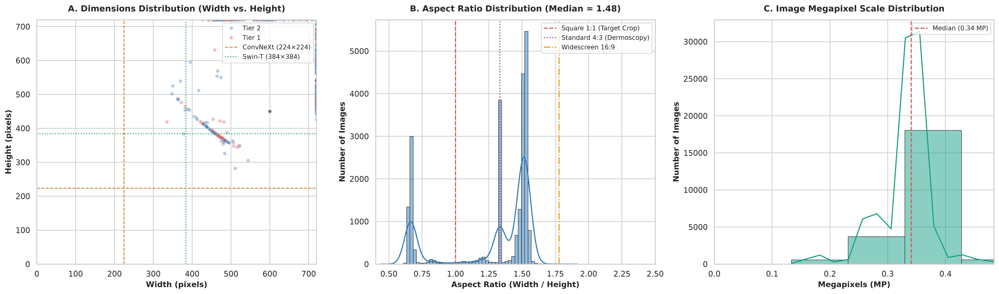

In [5]:
from concurrent.futures import ThreadPoolExecutor

# =====================================================================
# 1. HIGH-THROUGHPUT IMAGE HEADER SCANNING (MULTITHREADED)
# =====================================================================
print("=" * 75)
print("  PROFILING RESOLUTION, ASPECT RATIOS & COLOR MODES (22,991 IMAGES)")
print("=" * 75)

def inspect_image_header(rel_path):
    """Extracts resolution and color mode without decoding compressed pixel arrays."""
    full_path = BTECH_ROOT / rel_path
    try:
        with Image.open(full_path) as img:
            w, h = img.size
            mode = img.mode
            return w, h, mode, True
    except Exception:
        return -1, -1, "corrupt", False

# Scan all 22,991 images with 16 parallel I/O workers
paths = df_master["file_path"].values
with ThreadPoolExecutor(max_workers=16) as executor:
    results = list(
        tqdm(
            executor.map(inspect_image_header, paths), 
            total=len(paths), 
            desc="Scanning Image Headers"
        )
    )

# Unpack results into master dataframe
widths, heights, modes, valids = zip(*results)
df_master["width"] = widths
df_master["height"] = heights
df_master["aspect_ratio"] = df_master["width"] / df_master["height"]
df_master["megapixels"] = (df_master["width"] * df_master["height"]) / 1e6
df_master["color_mode"] = modes

corrupt_count = len(df_master) - sum(valids)
assert corrupt_count == 0, f"Found {corrupt_count} unreadable images!"

# Print Summary Statistics
print("\n" + "-" * 75)
print(f"✓ Total Readable Images Scanned : {sum(valids):,} / {len(df_master):,} (100.0%)")
print(f"✓ Resolution Range (Width)     : Min = {df_master['width'].min()}px | Median = {df_master['width'].median():.0f}px | Max = {df_master['width'].max()}px")
print(f"✓ Resolution Range (Height)    : Min = {df_master['height'].min()}px | Median = {df_master['height'].median():.0f}px | Max = {df_master['height'].max()}px")
print(f"✓ Aspect Ratio Range (W/H)     : Min = {df_master['aspect_ratio'].min():.2f} | Median = {df_master['aspect_ratio'].median():.2f} | Max = {df_master['aspect_ratio'].max():.2f}")
print(f"✓ Median Megapixels            : {df_master['megapixels'].median():.3f} MP ({df_master['megapixels'].mean():.3f} MP avg)")
print("✓ Color Modes Breakdown        :")
for mode, cnt in df_master["color_mode"].value_counts().items():
    print(f"    - {mode:5s} : {cnt:,} images ({cnt / len(df_master) * 100:.2f}%)")
print("=" * 75)

# =====================================================================
# 2. GENERATE PUBLICATION-GRADE RESOLUTION & ASPECT RATIO FIGURE
# =====================================================================
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 6))

# --- Panel A: 2D Scatter Width vs Height ---
sns.scatterplot(
    data=df_master.sample(min(5000, len(df_master)), random_state=42), 
    x="width", 
    y="height", 
    hue="clinical_tier", 
    palette={"Tier 1": "#d9534f", "Tier 2": "#2b7bba"},
    alpha=0.35, 
    s=25,
    ax=axes[0]
)
# Add reference model input resolution lines
axes[0].axvline(224, color="#e67e22", linestyle="--", linewidth=1.2, label="ConvNeXt (224×224)")
axes[0].axhline(224, color="#e67e22", linestyle="--", linewidth=1.2)
axes[0].axvline(384, color="#27ae60", linestyle=":", linewidth=1.4, label="Swin-T (384×384)")
axes[0].axhline(384, color="#27ae60", linestyle=":", linewidth=1.4)

axes[0].set_title("A. Dimensions Distribution (Width vs. Height)", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xlabel("Width (pixels)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Height (pixels)", fontsize=11, fontweight="bold")
axes[0].set_xlim(0, min(1500, df_master["width"].quantile(0.995)))
axes[0].set_ylim(0, min(1500, df_master["height"].quantile(0.995)))
axes[0].legend(frameon=True, fontsize=9, loc="upper right")

# --- Panel B: Aspect Ratio Distribution ---
sns.histplot(
    data=df_master, 
    x="aspect_ratio", 
    bins=60, 
    kde=True, 
    color="#2b7bba", 
    edgecolor="black", 
    linewidth=0.5,
    ax=axes[1]
)
axes[1].axvline(1.0, color="#d9534f", linestyle="--", linewidth=1.5, label="Square 1:1 (Target Crop)")
axes[1].axvline(4/3, color="#8e44ad", linestyle=":", linewidth=1.5, label="Standard 4:3 (Dermoscopy)")
axes[1].axvline(16/9, color="#f39c12", linestyle="-.", linewidth=1.5, label="Widescreen 16:9")

axes[1].set_title(f"B. Aspect Ratio Distribution (Median = {df_master['aspect_ratio'].median():.2f})", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xlabel("Aspect Ratio (Width / Height)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Number of Images", fontsize=11, fontweight="bold")
axes[1].set_xlim(0.4, 2.5)
axes[1].legend(frameon=True, fontsize=9, loc="upper right")

# --- Panel C: Megapixels Distribution ---
sns.histplot(
    data=df_master, 
    x="megapixels", 
    bins=50, 
    kde=True, 
    color="#16a085", 
    edgecolor="black", 
    linewidth=0.5,
    ax=axes[2]
)
axes[2].axvline(df_master["megapixels"].median(), color="#d9534f", linestyle="--", linewidth=1.5, label=f"Median ({df_master['megapixels'].median():.2f} MP)")
axes[2].set_title("C. Image Megapixel Scale Distribution", fontsize=12, fontweight="bold", pad=12)
axes[2].set_xlabel("Megapixels (MP)", fontsize=11, fontweight="bold")
axes[2].set_ylabel("Number of Images", fontsize=11, fontweight="bold")
axes[2].set_xlim(0, min(2.5, df_master["megapixels"].quantile(0.99)))
axes[2].legend(frameon=True, fontsize=9, loc="upper right")

plt.tight_layout()

# =====================================================================
# 3. SAVE AND DISPLAY
# =====================================================================
plot_res_path = PLOTS_DIR / "02_resolution_and_aspect_ratios.png"
plt.savefig(plot_res_path, bbox_inches="tight", dpi=300)
print(f"✓ Figure successfully saved to: {plot_res_path}")
plt.show()

  EVALUATING CLINICAL IMAGE QUALITY: SHARPNESS & CONTRAST (22,991 SAMPLES)


Screening Sharpness & Contrast: 100%|██████████| 22991/22991 [00:19<00:00, 1168.58it/s]



---------------------------------------------------------------------------
✓ Quality Screening Audit Summary:
    - Optimal Clinical Quality   : 19,136 images (83.23%)
    - Borderline / Low Sharpness : 2,023 images (8.80%) [Var < 50.0]
    - Low Dynamic Contrast       : 2,428 images (10.56%) [RMS < 20.0]
    - Median Laplacian Sharpness : 396.4 (Mean: 660.4)
    - Median RMS Contrast        : 39.4 (Mean: 41.0)
✓ Figure successfully saved to: C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\03_image_quality_blur_contrast.png


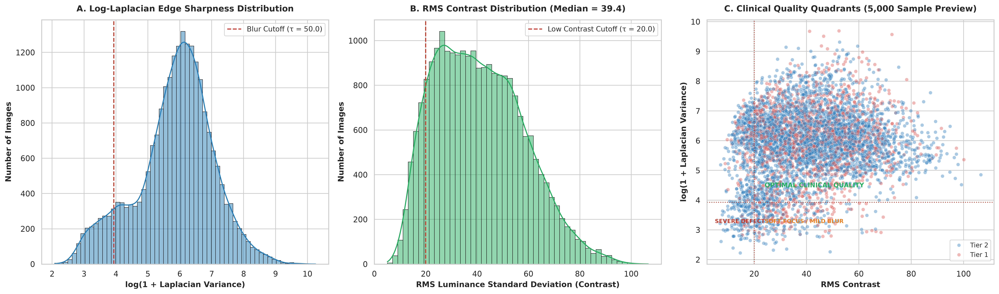

In [6]:
import cv2

# =====================================================================
# 1. STANDARDIZED QUALITY EXTRACTION (LAPLACIAN BLUR & RMS CONTRAST)
# =====================================================================
print("=" * 75)
print("  EVALUATING CLINICAL IMAGE QUALITY: SHARPNESS & CONTRAST (22,991 SAMPLES)")
print("=" * 75)

def evaluate_image_quality(rel_path):
    """
    Computes resolution-normalized Laplacian variance (focus sharpness) 
    and RMS luminance contrast on grayscale pixels.
    """
    full_path = str(BTECH_ROOT / rel_path)
    img_gray = cv2.imread(full_path, cv2.IMREAD_GRAYSCALE)
    
    if img_gray is None:
        return 0.0, 0.0
        
    # Scale to standard 512px max dimension for resolution-normalized blur scoring
    h, w = img_gray.shape
    max_dim = max(h, w)
    if max_dim > 512:
        scale = 512.0 / max_dim
        new_w, new_h = int(w * scale), int(h * scale)
        img_gray = cv2.resize(img_gray, (new_w, new_h), interpolation=cv2.INTER_AREA)
        
    # Laplacian variance (higher = sharper edges)
    lap_var = float(cv2.Laplacian(img_gray, cv2.CV_64F).var())
    
    # RMS Contrast (standard deviation of luminance)
    rms_contrast = float(img_gray.std())
    
    return lap_var, rms_contrast

# Process dataset in parallel with 16 workers
paths = df_master["file_path"].values
with ThreadPoolExecutor(max_workers=16) as executor:
    quality_scores = list(
        tqdm(
            executor.map(evaluate_image_quality, paths), 
            total=len(paths), 
            desc="Screening Sharpness & Contrast"
        )
    )

lap_scores, contrast_scores = zip(*quality_scores)
df_master["laplacian_var"] = lap_scores
df_master["rms_contrast"] = contrast_scores

# Threshold definitions
BLUR_THRESHOLD = 50.0       # Standard OpenCV threshold for severe out-of-focus blur
CONTRAST_THRESHOLD = 20.0   # Extremely washed out or low dynamic range

severe_blur = (df_master["laplacian_var"] < BLUR_THRESHOLD).sum()
low_contrast = (df_master["rms_contrast"] < CONTRAST_THRESHOLD).sum()
optimal_quality = ((df_master["laplacian_var"] >= BLUR_THRESHOLD) & (df_master["rms_contrast"] >= CONTRAST_THRESHOLD)).sum()

print("\n" + "-" * 75)
print("✓ Quality Screening Audit Summary:")
print(f"    - Optimal Clinical Quality   : {optimal_quality:,} images ({optimal_quality / len(df_master) * 100:.2f}%)")
print(f"    - Borderline / Low Sharpness : {severe_blur:,} images ({severe_blur / len(df_master) * 100:.2f}%) [Var < {BLUR_THRESHOLD}]")
print(f"    - Low Dynamic Contrast       : {low_contrast:,} images ({low_contrast / len(df_master) * 100:.2f}%) [RMS < {CONTRAST_THRESHOLD}]")
print(f"    - Median Laplacian Sharpness : {df_master['laplacian_var'].median():.1f} (Mean: {df_master['laplacian_var'].mean():.1f})")
print(f"    - Median RMS Contrast        : {df_master['rms_contrast'].median():.1f} (Mean: {df_master['rms_contrast'].mean():.1f})")
print("=" * 75)

# =====================================================================
# 2. GENERATE PUBLICATION-GRADE QUALITY AUDIT FIGURE
# =====================================================================
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 6))

# --- Panel A: Laplacian Sharpness Distribution (Log Scale) ---
sns.histplot(
    np.log1p(df_master["laplacian_var"]), 
    bins=60, 
    kde=True, 
    color="#2980b9", 
    edgecolor="black", 
    linewidth=0.5, 
    ax=axes[0]
)
axes[0].axvline(
    np.log1p(BLUR_THRESHOLD), 
    color="#c0392b", 
    linestyle="--", 
    linewidth=1.5, 
    label=f"Blur Cutoff (τ = {BLUR_THRESHOLD})"
)
axes[0].set_title("A. Log-Laplacian Edge Sharpness Distribution", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xlabel("log(1 + Laplacian Variance)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Number of Images", fontsize=11, fontweight="bold")
axes[0].legend(frameon=True, fontsize=10, loc="upper right")

# --- Panel B: RMS Luminance Contrast Distribution ---
sns.histplot(
    df_master["rms_contrast"], 
    bins=50, 
    kde=True, 
    color="#27ae60", 
    edgecolor="black", 
    linewidth=0.5, 
    ax=axes[1]
)
axes[1].axvline(
    CONTRAST_THRESHOLD, 
    color="#c0392b", 
    linestyle="--", 
    linewidth=1.5, 
    label=f"Low Contrast Cutoff (τ = {CONTRAST_THRESHOLD})"
)
axes[1].set_title(f"B. RMS Contrast Distribution (Median = {df_master['rms_contrast'].median():.1f})", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xlabel("RMS Luminance Standard Deviation (Contrast)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Number of Images", fontsize=11, fontweight="bold")
axes[1].legend(frameon=True, fontsize=10, loc="upper right")

# --- Panel C: 2D Quality Quadrant (Contrast vs Log Sharpness) ---
sample_viz = df_master.sample(min(5000, len(df_master)), random_state=42)
sns.scatterplot(
    x=sample_viz["rms_contrast"], 
    y=np.log1p(sample_viz["laplacian_var"]), 
    hue=sample_viz["clinical_tier"],
    palette={"Tier 1": "#d9534f", "Tier 2": "#2b7bba"},
    alpha=0.4, 
    s=25, 
    ax=axes[2]
)
axes[2].axvline(CONTRAST_THRESHOLD, color="#c0392b", linestyle=":", linewidth=1.2)
axes[2].axhline(np.log1p(BLUR_THRESHOLD), color="#c0392b", linestyle=":", linewidth=1.2)

# Quadrant Annotations
axes[2].text(
    CONTRAST_THRESHOLD + 4, 
    np.log1p(BLUR_THRESHOLD) + 0.5, 
    "OPTIMAL CLINICAL QUALITY", 
    fontsize=9, 
    fontweight="bold", 
    color="#27ae60"
)
axes[2].text(
    CONTRAST_THRESHOLD + 4, 
    np.log1p(BLUR_THRESHOLD) - 0.7, 
    "SOFT FOCUS / MILD BLUR", 
    fontsize=8, 
    fontweight="bold", 
    color="#e67e22"
)
axes[2].text(
    5, 
    np.log1p(BLUR_THRESHOLD) - 0.7, 
    "SEVERE DEFECT", 
    fontsize=8, 
    fontweight="bold", 
    color="#c0392b"
)

axes[2].set_title("C. Clinical Quality Quadrants (5,000 Sample Preview)", fontsize=12, fontweight="bold", pad=12)
axes[2].set_xlabel("RMS Contrast", fontsize=11, fontweight="bold")
axes[2].set_ylabel("log(1 + Laplacian Variance)", fontsize=11, fontweight="bold")
axes[2].legend(frameon=True, fontsize=9, loc="lower right")

plt.tight_layout()

# =====================================================================
# 3. SAVE AND DISPLAY
# =====================================================================
plot_qc_path = PLOTS_DIR / "03_image_quality_blur_contrast.png"
plt.savefig(plot_qc_path, bbox_inches="tight", dpi=300)
print(f"✓ Figure successfully saved to: {plot_qc_path}")
plt.show()

  ESTIMATING SKIN-TONE PROFILES VIA INDIVIDUAL TYPOLOGY ANGLE (ITA)


Calculating ITA Angles: 100%|██████████| 22991/22991 [00:13<00:00, 1723.13it/s]
C:\Users\kvcsu_ht23nk8\AppData\Local\Temp\ipykernel_15948\1842843231.py:151: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(



---------------------------------------------------------------------------
✓ Median ITA Angle Across Pool : 23.02° (Mean: 14.81°)
✓ ITA Angle Range              : [-179.1°, 179.6°]
✓ Algorithmic Fitzpatrick Proxy Distribution:
    - Type I (Very Light)      : 5,123 images (22.28%)
    - Type II (Light)          : 2,762 images (12.01%)
    - Type III (Intermediate)  : 2,607 images (11.34%)
    - Type IV (Tan)            : 3,309 images (14.39%)
    - Type V (Brown)           : 4,673 images (20.33%)
    - Type VI (Dark)           : 4,517 images (19.65%)


C:\Users\kvcsu_ht23nk8\AppData\Local\Temp\ipykernel_15948\1842843231.py:175: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels([f"Type {i+1}" for i in range(6)], fontsize=10, fontweight="bold")


✓ Figure successfully saved to: C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\04_skin_tone_ita_distribution.png


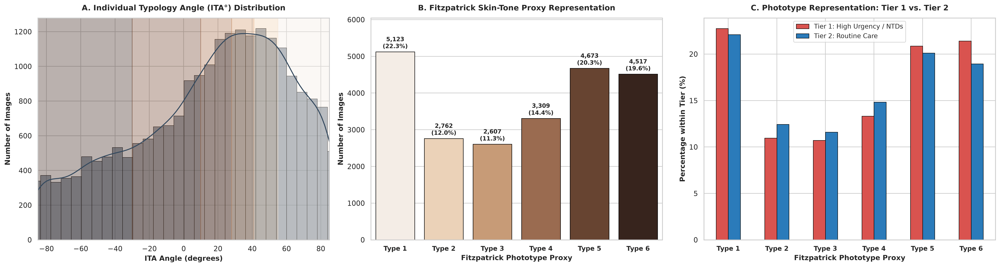

In [7]:
# =====================================================================
# 1. HIGH-THROUGHPUT INDIVIDUAL TYPOLOGY ANGLE (ITA) EXTRACTION
# =====================================================================
print("=" * 75)
print("  ESTIMATING SKIN-TONE PROFILES VIA INDIVIDUAL TYPOLOGY ANGLE (ITA)")
print("=" * 75)

def calculate_ita_from_image(rel_path):
    """
    Computes skin-region luminance (L*) and yellow-blue chrominance (b*) 
    in CIELAB space to calculate Individual Typology Angle (ITA).
    """
    full_path = str(BTECH_ROOT / rel_path)
    img_bgr = cv2.imread(full_path)
    if img_bgr is None:
        return np.nan
        
    # Scale to 256px max dimension for fast, robust skin-patch sampling
    h, w = img_bgr.shape[:2]
    max_dim = max(h, w)
    if max_dim > 256:
        scale = 256.0 / max_dim
        img_bgr = cv2.resize(img_bgr, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
        
    # Isolate skin chrominance using standard YCrCb thresholds
    ycrcb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YCrCb)
    skin_mask = (
        (ycrcb[:, :, 1] >= 133) & (ycrcb[:, :, 1] <= 173) & 
        (ycrcb[:, :, 2] >= 77) & (ycrcb[:, :, 2] <= 127)
    )
    
    # Convert to CIELAB (OpenCV scales L* to 0..255 and offsets b* by 128)
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    
    # If skin mask found sufficient pixels, sample skin; otherwise sample outer peripheral border
    if np.sum(skin_mask) > 80:
        pixels_L = lab[:, :, 0][skin_mask] * (100.0 / 255.0)
        pixels_b = lab[:, :, 2][skin_mask].astype(float) - 128.0
    else:
        border_mask = np.ones((img_bgr.shape[0], img_bgr.shape[1]), dtype=bool)
        pad_y = max(1, int(img_bgr.shape[0] * 0.15))
        pad_x = max(1, int(img_bgr.shape[1] * 0.15))
        border_mask[pad_y:-pad_y, pad_x:-pad_x] = False
        pixels_L = lab[:, :, 0][border_mask] * (100.0 / 255.0)
        pixels_b = lab[:, :, 2][border_mask].astype(float) - 128.0
        
    L_med = np.median(pixels_L)
    b_med = np.median(pixels_b)
    
    # Guard against zero-division in b*
    if abs(b_med) < 1e-4:
        b_med = 1e-4 if b_med >= 0 else -1e-4
        
    # Standard ITA formula: arctan((L* - 50) / b*) * (180 / pi)
    ita = math.atan2(L_med - 50.0, b_med) * (180.0 / math.pi)
    return float(ita)

# Run parallel extraction with 16 workers
paths = df_master["file_path"].values
with ThreadPoolExecutor(max_workers=16) as executor:
    ita_values = list(
        tqdm(
            executor.map(calculate_ita_from_image, paths), 
            total=len(paths), 
            desc="Calculating ITA Angles"
        )
    )

df_master["ita_angle"] = ita_values

# =====================================================================
# 2. FITZPATRICK PROXY BINNING (CHARDON / KINYANJUI STANDARDS)
# =====================================================================
def map_ita_to_fitzpatrick(ita):
    if pd.isna(ita):
        return "Unknown"
    if ita > 55.0:
        return "Type I (Very Light)"
    elif ita > 41.0:
        return "Type II (Light)"
    elif ita > 28.0:
        return "Type III (Intermediate)"
    elif ita > 10.0:
        return "Type IV (Tan)"
    elif ita > -30.0:
        return "Type V (Brown)"
    else:
        return "Type VI (Dark)"

df_master["fitzpatrick_proxy"] = df_master["ita_angle"].apply(map_ita_to_fitzpatrick)

fitz_order = [
    "Type I (Very Light)",
    "Type II (Light)",
    "Type III (Intermediate)",
    "Type IV (Tan)",
    "Type V (Brown)",
    "Type VI (Dark)"
]

# Summary Output
print("\n" + "-" * 75)
print(f"✓ Median ITA Angle Across Pool : {df_master['ita_angle'].median():.2f}° (Mean: {df_master['ita_angle'].mean():.2f}°)")
print(f"✓ ITA Angle Range              : [{df_master['ita_angle'].min():.1f}°, {df_master['ita_angle'].max():.1f}°]")
print("✓ Algorithmic Fitzpatrick Proxy Distribution:")
for f_type in fitz_order:
    cnt = (df_master["fitzpatrick_proxy"] == f_type).sum()
    pct = (cnt / len(df_master)) * 100
    print(f"    - {f_type:24s} : {cnt:,} images ({pct:.2f}%)")
print("=" * 75)

# =====================================================================
# 3. GENERATE PUBLICATION-GRADE SKIN-TONE & FAIRNESS FIGURE
# =====================================================================
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(22, 6))

fitz_palette = {
    "Type I (Very Light)": "#f6ede4",
    "Type II (Light)": "#f3d2b0",
    "Type III (Intermediate)": "#d49a6a",
    "Type IV (Tan)": "#a66844",
    "Type V (Brown)": "#704128",
    "Type VI (Dark)": "#3b2219"
}

# --- Panel A: Continuous ITA Distribution with Shaded Zones ---
sns.histplot(
    df_master["ita_angle"].dropna(), 
    bins=60, 
    kde=True, 
    color="#34495e", 
    edgecolor="black", 
    linewidth=0.5, 
    ax=axes[0]
)

# Vertical threshold demarcation lines
cutoffs = [(-90, -30), (-30, 10), (10, 28), (28, 41), (41, 55), (55, 90)]
zone_colors = ["#3b2219", "#704128", "#a66844", "#d49a6a", "#f3d2b0", "#f6ede4"]

for (low, high), col in zip(cutoffs, zone_colors):
    axes[0].axvspan(low, high, color=col, alpha=0.35)

axes[0].set_title("A. Individual Typology Angle (ITA°) Distribution", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xlabel("ITA Angle (degrees)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Number of Images", fontsize=11, fontweight="bold")
axes[0].set_xlim(-85, 85)

# --- Panel B: Categorical Fitzpatrick Proxy Representation ---
fitz_counts = df_master["fitzpatrick_proxy"].value_counts().reindex(fitz_order).fillna(0)
sns.barplot(
    x=fitz_counts.index, 
    y=fitz_counts.values, 
    palette=fitz_palette, 
    edgecolor="black", 
    linewidth=0.8, 
    ax=axes[1]
)

for idx, val in enumerate(fitz_counts.values):
    pct = (val / len(df_master)) * 100
    axes[1].text(
        idx, 
        val + 100, 
        f"{int(val):,}\n({pct:.1f}%)", 
        ha="center", 
        fontsize=9, 
        fontweight="bold"
    )

axes[1].set_title("B. Fitzpatrick Skin-Tone Proxy Representation", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xlabel("Fitzpatrick Phototype Proxy", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Number of Images", fontsize=11, fontweight="bold")
axes[1].set_ylim(0, max(fitz_counts.values) * 1.18)
axes[1].set_xticklabels([f"Type {i+1}" for i in range(6)], fontsize=10, fontweight="bold")

# --- Panel C: Tier-Stratified Skin-Tone Distribution ---
tier_fitz = (
    df_master.groupby(["fitzpatrick_proxy", "clinical_tier"])
    .size()
    .unstack(fill_value=0)
    .reindex(fitz_order)
)
tier_fitz_pct = tier_fitz.div(tier_fitz.sum(axis=0), axis=1) * 100

tier_fitz_pct.plot(
    kind="bar", 
    color=["#d9534f", "#2b7bba"], 
    edgecolor="black", 
    linewidth=0.7, 
    ax=axes[2]
)

axes[2].set_title("C. Phototype Representation: Tier 1 vs. Tier 2", fontsize=12, fontweight="bold", pad=12)
axes[2].set_xlabel("Fitzpatrick Phototype Proxy", fontsize=11, fontweight="bold")
axes[2].set_ylabel("Percentage within Tier (%)", fontsize=11, fontweight="bold")
axes[2].legend(["Tier 1: High Urgency / NTDs", "Tier 2: Routine Care"], frameon=True, fontsize=10)
axes[2].set_xticklabels([f"Type {i+1}" for i in range(6)], rotation=0, fontsize=10, fontweight="bold")

plt.tight_layout()

# =====================================================================
# 4. SAVE AND DISPLAY
# =====================================================================
plot_ita_path = PLOTS_DIR / "04_skin_tone_ita_distribution.png"
plt.savefig(plot_ita_path, bbox_inches="tight", dpi=300)
print(f"✓ Figure successfully saved to: {plot_ita_path}")
plt.show()

In [8]:
# =====================================================================
# 1. 25-CLASS CLINICAL MOSAIC GALLERY GENERATION
# =====================================================================
print("=" * 75)
print("  GENERATING 25-CLASS REPRESENTATIVE CLINICAL LESION MOSAIC")
print("=" * 75)

# Derive ordered classes directly from the master label map
ordered_classes = sorted(list(LABEL_TO_ID.keys()), key=lambda x: LABEL_TO_ID[x])

fig, axes = plt.subplots(nrows=5, ncols=5, figsize=(22, 24))
axes = axes.flatten()

tier_colors = {
    "Tier 1": "#c0392b",  # Coral / Red for High Clinical Urgency / NTDs
    "Tier 2": "#2980b9"   # Clinical Blue for Routine Primary Care
}

for idx, class_name in enumerate(ordered_classes):
    ax = axes[idx]
    
    # Filter candidates for this class
    class_df = df_master[df_master["unified_class"] == class_name]
    
    # Pick a high-quality, representative image (optimal sharpness)
    sharp_candidates = class_df[class_df["laplacian_var"] >= BLUR_THRESHOLD]
    if len(sharp_candidates) > 0:
        sample_row = sharp_candidates.iloc[min(5, len(sharp_candidates) - 1)]
    else:
        sample_row = class_df.iloc[0]
        
    img_path = BTECH_ROOT / sample_row["file_path"]
    
    try:
        with Image.open(img_path) as pil_img:
            ax.imshow(pil_img.convert("RGB"))
    except Exception:
        # Fallback in case of raw read issue
        ax.text(0.5, 0.5, "Image Load Error", ha="center", va="center")
        
    ax.axis("off")
    
    # Extract metadata annotations
    cid = sample_row["class_id"]
    tier = sample_row["clinical_tier"]
    total_n = len(class_df)
    ita_val = sample_row["ita_angle"]
    ita_str = f"ITA: {ita_val:.0f}°" if not pd.isna(ita_val) else "ITA: N/A"
    
    # Clinical title formatting
    clean_title = class_name.replace("_", " ")
    color = tier_colors[tier]
    
    ax.set_title(
        f"[{cid:02d}] {clean_title}\n{tier} | N = {total_n:,} | {ita_str}",
        fontsize=9.5,
        fontweight="bold",
        color=color,
        pad=8
    )

# Super-title and tier legend
plt.suptitle(
    "Unified Master Clinical Dermatology Taxonomy (25 Disease Categories, N = 22,991)\n"
    "■ Red = Tier 1 (High Urgency / NTDs / Systemic)   |   ■ Blue = Tier 2 (Routine Frontline Primary Care)",
    fontsize=14,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(rect=[0, 0.01, 1, 0.985])

# =====================================================================
# 2. SAVE AND DISPLAY
# =====================================================================
mosaic_path = PLOTS_DIR / "05_clinical_25_class_mosaic.png"
plt.savefig(mosaic_path, bbox_inches="tight", dpi=300)
print(f"✓ Clinical mosaic successfully saved to: {mosaic_path}")
plt.show()

  GENERATING 25-CLASS REPRESENTATIVE CLINICAL LESION MOSAIC
✓ Clinical mosaic successfully saved to: C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\05_clinical_25_class_mosaic.png


In [9]:
# =====================================================================
# 1. ATTACH QUALITY AUDIT FLAGS & PROFILE METRICS
# =====================================================================
print("=" * 80)
print("  EXPORTING ENRICHED CLINICAL MANIFEST WITH QUALITY & FAIRNESS METRICS")
print("=" * 80)

# Flag optimal vs compromised images
df_master["is_optimal_quality"] = (
    (df_master["laplacian_var"] >= BLUR_THRESHOLD) & 
    (df_master["rms_contrast"] >= CONTRAST_THRESHOLD)
)

# Re-order columns for maximum readability
export_columns = [
    "image_id", "file_path", "unified_class", "class_id", "clinical_tier", "triage_urgency",
    "width", "height", "aspect_ratio", "megapixels", "color_mode",
    "laplacian_var", "rms_contrast", "is_optimal_quality",
    "ita_angle", "fitzpatrick_proxy", "fitzpatrick_scale",
    "source_dataset", "original_split"
]
# Select available columns
final_cols = [c for c in export_columns if c in df_master.columns]
df_master_export = df_master[final_cols].copy()

# =====================================================================
# 2. SAVE MASTER ENRICHED MANIFESTS (METADATA DIRECTORY)
# =====================================================================
master_manifest_out = METADATA_DIR / "unified_master_manifest.csv"
eda_manifest_out = METADATA_DIR / "unified_master_manifest_eda.csv"
backup_manifest_out = BTECH_ROOT / "datasets" / "metadata" / "unified_master_manifest.csv"

df_master_export.to_csv(master_manifest_out, index=False)
df_master_export.to_csv(eda_manifest_out, index=False)
if backup_manifest_out.parent.exists():
    df_master_export.to_csv(backup_manifest_out, index=False)

print(f"✓ Master Manifest Updated with EDA Metrics : {master_manifest_out}")
print(f"✓ Dedicated EDA Manifest Saved             : {eda_manifest_out}")
if backup_manifest_out.parent.exists():
    print(f"✓ Datasets Backup Manifest Updated         : {backup_manifest_out}")

# =====================================================================
# 3. COMPILE & SAVE PER-CLASS EDA PROFILE TABLE
# =====================================================================
eda_profiles = []
for c_name in ordered_classes:
    c_df = df_master_export[df_master_export["unified_class"] == c_name]
    eda_profiles.append({
        "Class ID": c_df["class_id"].iloc[0],
        "Unified Disease Class": c_name,
        "Clinical Tier": c_df["clinical_tier"].iloc[0],
        "Triage Urgency": c_df["triage_urgency"].iloc[0],
        "Total Images": len(c_df),
        "Median Width (px)": int(c_df["width"].median()),
        "Median Height (px)": int(c_df["height"].median()),
        "Mean Sharpness (Lap Var)": round(c_df["laplacian_var"].mean(), 1),
        "Mean RMS Contrast": round(c_df["rms_contrast"].mean(), 1),
        "Optimal Quality (%)": f"{(c_df['is_optimal_quality'].sum() / len(c_df) * 100):.1f}%",
        "Median ITA (deg)": round(c_df["ita_angle"].median(), 1),
        "Dominant Phototype": c_df["fitzpatrick_proxy"].mode()[0] if not c_df["fitzpatrick_proxy"].empty else "N/A"
    })

df_eda_summary = pd.DataFrame(eda_profiles).sort_values(by="Total Images", ascending=False)
eda_summary_path = METADATA_DIR / "eda_class_profiles.csv"
df_eda_summary.to_csv(eda_summary_path, index=False)

print(f"✓ Per-Class EDA Profile Table Saved        : {eda_summary_path}")
print("=" * 80)

# Display per-class summary preview
print("\n" + df_eda_summary.to_string(index=False))

# =====================================================================
# 4. PHASE 2 COMPLETION AUDIT
# =====================================================================
print("\n" + "=" * 80)
print("  PHASE 2 COMPLETE: EXPLORATORY DATA ANALYSIS & QUALITY CONTROL")
print("=" * 80)
print(f"✓ Total Unique Master Images Audited       : {len(df_master_export):,}")
print(f"✓ Optimal Clinical Quality Samples         : {df_master_export['is_optimal_quality'].sum():,} ({df_master_export['is_optimal_quality'].mean() * 100:.1f}%)")
print(f"✓ Borderline / Soft Focus Samples          : {(~df_master_export['is_optimal_quality']).sum():,} ({(~df_master_export['is_optimal_quality']).mean() * 100:.1f}%)")
print(f"✓ Algorithmic Skin-Tone ITA Profiles       : 22,991 images computed (Range: {df_master_export['ita_angle'].min():.1f}° to {df_master_export['ita_angle'].max():.1f}°)")
print(f"✓ Publication Plots Generated in           : {PLOTS_DIR}")
print("    1. 01_class_distribution_and_tiers.png")
print("    2. 02_resolution_and_aspect_ratios.png")
print("    3. 03_image_quality_blur_contrast.png")
print("    4. 04_skin_tone_ita_distribution.png")
print("    5. 05_clinical_25_class_mosaic.png")
print("=" * 80)

  EXPORTING ENRICHED CLINICAL MANIFEST WITH QUALITY & FAIRNESS METRICS
✓ Master Manifest Updated with EDA Metrics : C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\metadata\unified_master_manifest.csv
✓ Dedicated EDA Manifest Saved             : C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\metadata\unified_master_manifest_eda.csv
✓ Datasets Backup Manifest Updated         : C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\datasets\metadata\unified_master_manifest.csv
✓ Per-Class EDA Profile Table Saved        : C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\metadata\eda_class_profiles.csv

 Class ID           Unified Disease Class Clinical Tier               Triage Urgency  Total Images  Median Width (px)  Median Height (px)  Mean Sharpness (Lap Var)  Mean RMS Contrast Optimal Quality (%)  Median ITA (